In [ ]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [1]:
import pandas as pd
df = pd.read_csv('course_lead_scoring_2026.csv')

In [ ]:
df.head()

In [ ]:
df.isnull().sum()

In [ ]:
df.dtypes

In [ ]:
categorical_columns = df.select_dtypes(include=['object']).columns
numerical_columns = df.columns.difference(categorical_columns).tolist()


In [4]:
categorical_columns.tolist()

['lead_source', 'industry', 'employment_status', 'location']

In [ ]:
numerical_columns

In [ ]:
df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0)

### Dataset Splitting ###

In [65]:
from utils import split_dataset

# train / val / test (60/20/20)
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(
    df, target='converted', test_size=0.2, val_size=0.2, random_state=1
)

In [ ]:
from sklearn.metrics import roc_auc_score

numerical = X_train.select_dtypes("number").columns   # or list them explicitly

numerical  # or list them explicitly

In [133]:
for col in numerical:
    auc = roc_auc_score(y_train, X_train[col])
    if auc < 0.5:                                        # reverse relationship → invert
        auc = roc_auc_score(y_train, -X_train[col])
        print(f"{col:>10}: {auc:.3f} (inverted)")
    else:
        print(f"{col:>10}: {auc:.3f} (Regular)")

annual_income: 0.608 (Regular)
number_of_courses_viewed: 0.723 (Regular)
interaction_count: 0.765 (Regular)
lead_score: 0.788 (Regular)


### Question 2 ###

In [66]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

dv = DictVectorizer(sparse=False)

train_dicts = X_train.to_dict(orient='records')
X_train_enc = dv.fit_transform(train_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train_enc, y_train)

# validation: transform only, never fit again
val_dicts = X_val.to_dict(orient='records')
X_val_enc = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val_enc)[:, 1]
print(round(roc_auc_score(y_val, y_pred), 3))


0.732


### Random Model ###

In [67]:
import numpy as np
np.random.seed(1)

In [ ]:
y_random = np.random.uniform(0, 1, size=len(y_val))
y_random.round(3)

In [72]:
((y_random >= 0.5) == y_val).mean().item()  # accuracy

0.506

In [76]:
confusion_table = pd.DataFrame(
    [[tp, fn],
     [fp, tn]],
    index=['True Positive', 'False Negative'],
    columns=['False Positive', 'True Negative'],
)
confusion_table


,False Positive,True Negative
True Positive,531,55
False Negative,294,120


In [91]:
def tpr_fpr(y_val, y_pred, threshold=0.5):

    scores = []
    thresholds = np.linspace(0, 1, 101)
    for threshold in thresholds:
        pred_pos = (y_pred >= threshold)
        pred_neg = (y_pred < threshold)

        actual_pos = (y_val == 1)
        actual_neg = (y_val == 0)
        
        tn = (pred_neg & actual_neg).sum()
        fp = (pred_pos & actual_neg).sum()
        fn = (pred_neg & actual_pos).sum()
        tp = (pred_pos & actual_pos).sum()

        scores.append((threshold, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)
    scores = np.array(scores)

    df_scores['tpr'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
    df_scores['fpr'] = df_scores['fp'] / (df_scores['fp'] + df_scores['tn'])

    return df_scores

In [ ]:
tpr_fpr_rand = tpr_fpr(y_val, y_random).round(3)
tpr_fpr_rand[:10]

In [ ]:
from matplotlib import pyplot as plt

df_model = tpr_fpr(y_val, y_pred)
df_rand  = tpr_fpr(y_val, y_random)

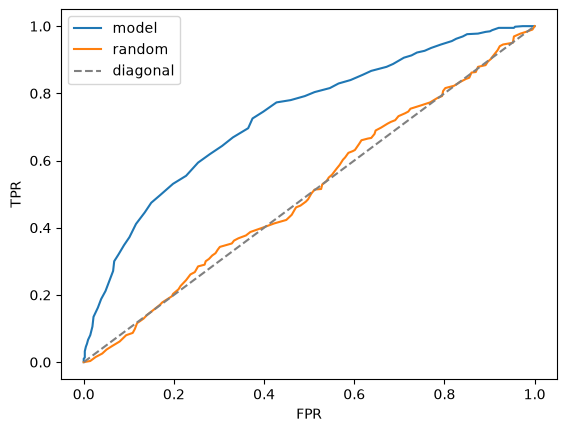

In [87]:

for d in (df_model, df_rand):
    d['accuracy'] = (d.tp + d.tn) / (d.tp + d.fp + d.fn + d.tn)

plt.plot(df_model.fpr, df_model.tpr, label='model')
plt.plot(df_rand.fpr, df_rand.tpr, label='random')
plt.plot([0, 1], [0, 1], '--', color='grey', label='diagonal')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend()


### Benchmarking Model ###

In [86]:
from sklearn.metrics import auc

df_model = tpr_fpr(y_val, y_pred)
df_rand  = tpr_fpr(y_val, y_random)

# AUC measures the area under the ROC curve. 
# The higher the AUC, the better the model is 
# at distinguishing between positive and negative classes.
true_model_auc = auc(df_model.fpr, df_model.tpr)
random_model_auc = auc(df_rand.fpr, df_rand.tpr)

print(f"Model AUC (from table) : {auc(df_model.fpr, df_model.tpr):.3f}")
print(f"Random AUC (from table): {auc(df_rand.fpr, df_rand.tpr):.3f}")

if true_model_auc > random_model_auc:
    print("The model already performs better than random.")
else:
    print("The model does not perform better than random.")

Model AUC (from table) : 0.732
Random AUC (from table): 0.508
The model already performs better than random.


In [98]:
actual_pos = (y_val == 1).sum()
actual_neg = (y_val == 0).sum()

y_ideal = np.repeat([0,1], [actual_pos, actual_neg]) # all ones

y_ideal_predict = np.linspace(0, 1, len(y_val))

accuracy_ideal = ((y_ideal_predict >= 0.732) == y_ideal).mean()
accuracy_ideal.item()  # ideal predictions

0.854

In [99]:
1 - y_val.mean()

np.float64(0.41400000000000003)

### Precision and Recall ###

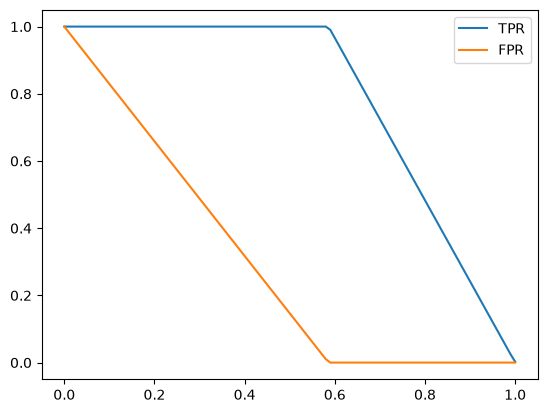

In [100]:
df_ideal = tpr_fpr(y_ideal, y_ideal_predict)
plt.plot(df_ideal.threshold, df_ideal['tpr'], label = 'TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label = 'FPR')
plt.legend()

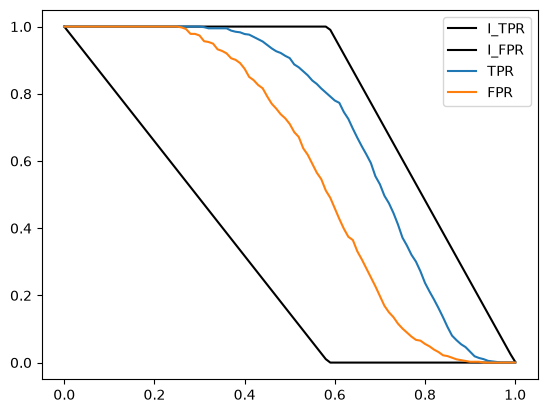

In [106]:
df_ideal = tpr_fpr(y_ideal, y_ideal_predict)
plt.plot(df_ideal.threshold, df_ideal['tpr'], label = 'I_TPR', color = 'black')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label = 'I_FPR', color = 'black')

# plt.plot(df_rand.threshold, df_rand['tpr'], label = 'R_TPR')
# plt.plot(df_rand.threshold, df_rand['fpr'], label = 'R_FPR')

plt.plot(df_model.threshold, df_model['tpr'], label = 'TPR')
plt.plot(df_model.threshold, df_model['fpr'], label = 'FPR')

plt.legend()

### ROC Curve ###

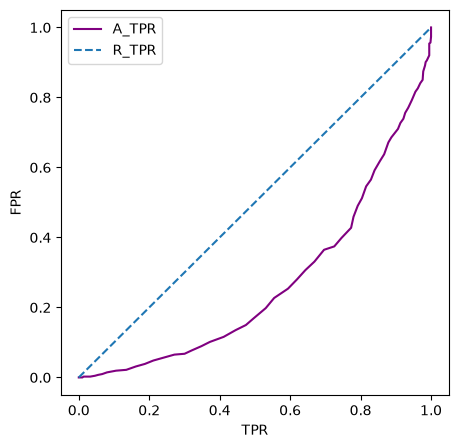

In [120]:
plt.figure(figsize=(5,5))
# plt.plot(df_ideal.tpr, df_ideal.fpr, label = 'I_TPR', color = 'Orange')
plt.plot(df_model.tpr, df_model.fpr, label = 'A_TPR', color = 'Purple')
# plt.plot(df_rand.tpr, df_rand.fpr, label = 'R_TPR', color = 'Green')
plt.plot([0,1], [0,1], label = 'R_TPR', linestyle = '--')

plt.xlabel('TPR')
plt.ylabel('FPR')

plt.legend()

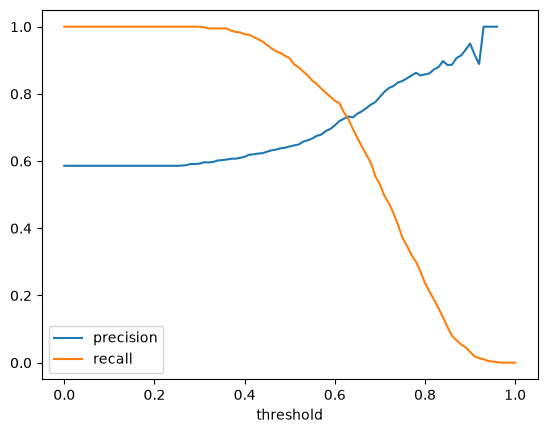

In [121]:
df_scores = tpr_fpr(y_val, y_pred)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend()


# Recall starts at 1.0 and falls as the threshold rises
# Precision generally rises, because the convserion you do make are more confident.

In [123]:
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

for t in thresholds:
    pred_pos = (y_pred >= t)

    tp = (pred_pos & (y_val == 1)).sum()
    fp = (pred_pos & (y_val == 0)).sum()
    fn = (~pred_pos & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn)

    scores.append((t, precision, recall))

df_pr = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])
df_pr.round(3)



,threshold,precision,recall
0,0.00,0.586,1.000
1,0.01,0.586,1.000
2,0.02,0.586,1.000
3,0.03,0.586,1.000
4,0.04,0.586,1.000
...,...,...,...
96,0.96,1.000,0.002
97,0.97,0.000,0.000
98,0.98,0.000,0.000
99,0.99,0.000,0.000


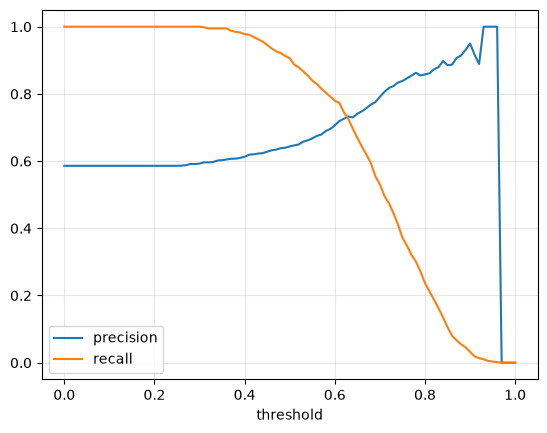

In [124]:
plt.plot(df_pr.threshold, df_pr.precision, label='precision')
plt.plot(df_pr.threshold, df_pr.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=0.3)


In [125]:
cross = df_pr[df_pr.precision >= df_pr.recall].iloc[0]   # first threshold where precision catches up
cross


threshold    0.630000
precision    0.732759
recall       0.725256
Name: 63, dtype: float64

In [129]:
df_pr['f1'] = 2 * df_pr.precision * df_pr.recall / (df_pr.precision + df_pr.recall)
df_pr['f1'] = df_pr['f1'].fillna(0)   # where P = R = 0, 0/0 gives NaN

best = df_pr.loc[df_pr.f1.idxmax()]
round(best.threshold.item(), 3)


0.41

In [137]:
from sklearn.metrics import auc
round(auc(df_model['fpr'], df_model['tpr']), 9)

0.731560485

In [138]:
round(roc_auc_score(y_val, y_pred),9)

0.731822229

### AUC interpretation ###

In [146]:
pos = y_pred[y_val == 1]
neg = y_pred[y_val == 0]

import random
success = 0
iterations = 20000

for i in range(iterations):
    rand_pos =random.randint(0, len(
        pos
    ) - 1)
    rand_neg =random.randint(0, len(
            pos
    ) - 1)
    if pos[rand_pos] > pos[rand_neg]:
        success = success + 1

success / iterations

0.5082